# Section 1: Knowledge Graph Design

## Aim of this Notebook
This notebook constructs the Cyber Threat Intelligence Knowledge Graph from the
validated entity and relation records identified in Notebook 1, and produces the
graph artefact used by all later notebooks.

### Graph Model

- Graph type: Directed graph
- Node: CTI entity
- Edge: CTI relation
- Node attribute: entity type
- Edge attribute: relation type

A directed graph is used because CTI relationships have direction.

Example:

Threat Actor -> uses -> Malware  
Malware -> exploits -> Vulnerability  
Malware -> communicates-with -> Infrastructure  

This design directly supports relationship-aware CTI analysis, graph analytics, threat-pattern discovery, and later classification.

### Project Setup

In [1]:
# ============================================================
# SECTION 2: PROJECT SETUP
# ============================================================

import json
import pickle
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

DATA_DIR= Path("../data/archive")
OUTPUT_DIR= Path("../outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DATASET_PATH= DATA_DIR / "all.jsonl"

print("Dataset path:", DATASET_PATH)
print("Output directory:", OUTPUT_DIR)

Dataset path: ..\data\archive\all.jsonl
Output directory: ..\outputs


### Load CTI Dataset

In [2]:

# SECTION 3: LOAD CTI DATASET

def load_jsonl(path):
    records= []

    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            if line.strip():
                records.append(json.loads(line))

    return pd.DataFrame(records)


df_all= load_jsonl(DATASET_PATH)

print("Dataset loaded successfully")
print("Total reports:", len(df_all))
print("Columns:", df_all.columns.tolist())

display(df_all.head())

Dataset loaded successfully
Total reports: 9732
Columns: ['id', 'text', 'entities', 'relations', 'Comments']


,id,text,entities,relations,Comments
0,1,This post is also available in: 日本語 (Japa...,"[{'id': 45800, 'label': 'malware', 'start_offs...",[],[]
1,2,The attack vector is very basic and repeats it...,"[{'id': 48941, 'label': 'attack-pattern', 'sta...",[],[]
2,3,Once executed by the user the first stage malw...,[],[],[]
3,4,The first known campaign was launched by Crim...,"[{'id': 45806, 'label': 'TIME', 'start_offset'...",[],[]
4,5,The first stage downloaded the ransomware from...,[],[],[]


### Graph Schema Validation

In [3]:

# SECTION 4: GRAPH SCHEMA VALIDATION
# used to calculate the reports, nodes, edges and its types for graph construction

total_reports = len(df_all)

reports_with_entities = df_all["entities"].apply(lambda x: len(x) > 0).sum()
reports_with_relations = df_all["relations"].apply(lambda x: len(x) > 0).sum()

total_entities= df_all["entities"].apply(len).sum()
total_relations= df_all["relations"].apply(len).sum()

entity_labels= []
relation_types = []

for entity_list in df_all["entities"]:
    for entity in entity_list:
        entity_labels.append(entity["label"])

for relation_list in df_all["relations"]:
    for relation in relation_list:
        relation_types.append(relation["type"])

unique_entity_types= sorted(set(entity_labels))
unique_relation_types= sorted(set(relation_types))

schema_summary = pd.DataFrame([
    ["Total reports", total_reports],
    ["Reports with entities", reports_with_entities],
    ["Reports with relations", reports_with_relations],
    ["Total entities", total_entities],
    ["Total relations", total_relations],
    ["Unique entity types", len(unique_entity_types)],
    ["Unique relation types", len(unique_relation_types)]
], columns=["Metric", "Value"])

display(schema_summary)

,Metric,Value
0,Total reports,9732
1,Reports with entities,4731
2,Reports with relations,480
3,Total entities,12679
4,Total relations,1095
5,Unique entity types,20
6,Unique relation types,25


### Build Entity Lookup Table
Relations reference entities only by ID, so a lookup table is needed that maps each
entity ID to its type and source report before edges can be constructed.

In [4]:

# SECTION 5: BUILD ENTITY LOOKUP TABLE

# here entities are converted into node  and its extracted from every report 
entity_records= []

for _, row in df_all.iterrows():

    report_id= row["id"]

    for entity in row["entities"]:

        entity_records.append({
            "entity_id": entity.get("id"),
            "entity_type": entity.get("label"),
            "start_offset": entity.get("start_offset"),
            "end_offset": entity.get("end_offset"),
            "report_id": report_id})

entity_df= pd.DataFrame(entity_records)

print("Total entity records:", len(entity_df))
print("Unique entity IDs:", entity_df["entity_id"].nunique())

display(entity_df.head())

Total entity records: 12679
Unique entity IDs: 12679


,entity_id,entity_type,start_offset,end_offset,report_id
0,45800,malware,288,300,1
1,45801,malware,53,63,1
2,45802,malware,342,352,1
3,48941,attack-pattern,69,115,2
4,45806,TIME,55,68,4


### Build Relation Table

In [5]:

# SECTION 6: BUILD RELATION TABLE

## extracted every relation and converted it into edges 

relation_records= []

for _, row in df_all.iterrows():

    report_id = row["id"]

    for relation in row["relations"]:

        relation_records.append({
            "relation_id": relation.get("id"),
            "source_id": relation.get("from_id"),  #source_id is the starting entity
            "target_id": relation.get("to_id"),  #ending entity
            "relation_type": relation.get("type"),  #edge label
            "report_id": report_id
        })

relation_df = pd.DataFrame(relation_records)

print("Total relation records:", len(relation_df))
print("Unique relation types:", relation_df["relation_type"].nunique())

display(relation_df.head())

Total relation records: 1095
Unique relation types: 25


,relation_id,source_id,target_id,relation_type,report_id
0,1,44599,44600,uses,105
1,2,44600,44601,exfiltrates-to,105
2,3,44599,44601,exfiltrates-to,105
3,120,45834,45835,uses,106
4,121,45834,45836,uses,106


### Check Relation Integrity

In [6]:

# SECTION 7: RELATION INTEGRITY CHECK

#making sure every entity is connnected by every relationship

entity_ids = set(entity_df["entity_id"])

relation_df["source_exists"] = relation_df["source_id"].isin(entity_ids)
relation_df["target_exists"] = relation_df["target_id"].isin(entity_ids)

valid_relations = relation_df[
    (relation_df["source_exists"] == True) &
    (relation_df["target_exists"] == True)
].copy()

invalid_relations = relation_df[
    (relation_df["source_exists"] == False) |
    (relation_df["target_exists"] == False)
].copy()

print("Total relations:", len(relation_df))
print("Valid relations:", len(valid_relations))
print("Invalid relations:", len(invalid_relations))

display(invalid_relations.head())

Total relations: 1095
Valid relations: 1095
Invalid relations: 0


,relation_id,source_id,target_id,relation_type,report_id,source_exists,target_exists


### Construct Directed CTI Knowledge Graph
Nodes are constructed at mention level — each node corresponds to a single raw
annotation `entity_id`, not a resolved real-world entity. This means repeated
mentions of the same malware, actor, or artefact across reports currently appear
as separate nodes. This design choice is intentional at this stage (it preserves
full provenance) and is revisited directly in Notebook 4, where mention-level
nodes are canonicalised into resolved entities.

In [7]:

# SECTION 8: CONSTRUCT DIRECTED CTI KNOWLEDGE GRAPH

G= nx.DiGraph()

# Add nodes
for _, entity in entity_df.iterrows():

    node_id= entity["entity_id"]

    G.add_node(
        node_id,
        entity_type=entity["entity_type"],
        report_id=entity["report_id"],
        start_offset=entity["start_offset"],
        end_offset=entity["end_offset"]
    )

# Add edges
for _, relation in valid_relations.iterrows():

    G.add_edge(
        relation["source_id"],
        relation["target_id"],
        relation_type=relation["relation_type"],
        relation_id=relation["relation_id"],
        report_id=relation["report_id"]
    )

print("Knowledge Graph constructed successfully")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Knowledge Graph constructed successfully
Number of nodes: 12679
Number of edges: 1094


### Graph Validation

In [8]:
# SECTION 9: GRAPH VALIDATION
# to ensure graph was constructed properly

graph_summary= pd.DataFrame([
    ["Nodes", G.number_of_nodes()],
    ["Edges", G.number_of_edges()],
    ["Density", nx.density(G)],
    ["Is directed", G.is_directed()],
    ["Self-loops", nx.number_of_selfloops(G)],
    ["Weakly connected components", nx.number_weakly_connected_components(G)]
], columns=["Metric", "Value"])

display(graph_summary)

,Metric,Value
0,Nodes,12679
1,Edges,1094
2,Density,0.000007
3,Is directed,True
4,Self-loops,0
5,Weakly connected components,11672


### Node and Edge Type Distribution

,entity_type,count
6,location,3137
0,malware,1750
1,attack-pattern,1380
4,SOFTWARE,1246
3,identity,1160
5,threat-actor,870
8,FILEPATH,500
2,TIME,486
7,tools,454
9,SHA2,453


,relation_type,count
0,uses,192
4,duplicate-of,181
6,indicates,156
3,targets,145
7,related-to,96
16,located-at,76
13,has,62
11,exploits,35
5,attributed-to,23
12,authored-by,23


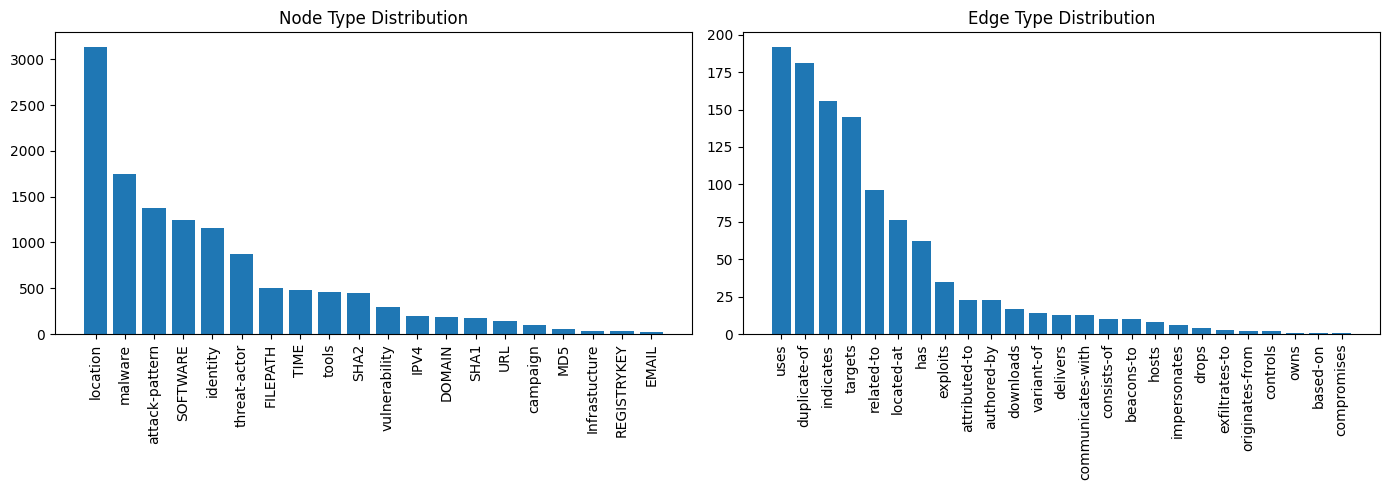

In [9]:
# SECTION 10: NODE AND EDGE TYPE DISTRIBUTION
node_type_counts = Counter(nx.get_node_attributes(G, "entity_type").values())
edge_type_counts = Counter(nx.get_edge_attributes(G, "relation_type").values())

node_type_df = pd.DataFrame(node_type_counts.items(), columns=["entity_type", "count"]).sort_values("count", ascending=False)
edge_type_df = pd.DataFrame(edge_type_counts.items(), columns=["relation_type", "count"]).sort_values("count", ascending=False)

display(node_type_df)
display(edge_type_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(node_type_df["entity_type"], node_type_df["count"])
axes[0].set_title("Node Type Distribution")
axes[0].tick_params(axis="x", rotation=90)

axes[1].bar(edge_type_df["relation_type"], edge_type_df["count"])
axes[1].set_title("Edge Type Distribution")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kg_node_edge_type_distribution.png", dpi=300)
plt.show()

### Outputs

In [10]:
# ============================================================
# SECTION 11: SAVE KNOWLEDGE GRAPH OUTPUTS
# ============================================================

with open(OUTPUT_DIR / "cti_knowledge_graph.pkl", "wb") as file:
    pickle.dump(G, file)

entity_df.to_csv(
    OUTPUT_DIR / "kg_entities.csv",
    index=False
)

relation_df.to_csv(
    OUTPUT_DIR / "kg_relations_all.csv",
    index=False
)

valid_relations.to_csv(
    OUTPUT_DIR / "kg_relations_valid.csv",
    index=False
)

graph_summary.to_csv(
    OUTPUT_DIR / "kg_graph_summary.csv",
    index=False
)

node_type_df.to_csv(
    OUTPUT_DIR / "kg_node_type_distribution.csv",
    index=False
)

edge_type_df.to_csv(
    OUTPUT_DIR / "kg_edge_type_distribution.csv",
    index=False
)

print("Knowledge Graph and outputs saved successfully.")

Knowledge Graph and outputs saved successfully.


## Conclusion
The Cyber Threat Intelligence Knowledge Graph was constructed as a directed graph
with mention-level nodes: 12,679 nodes and 1,094 valid relations, drawn from 9,732
reports. Graph density is extremely low and the graph is highly fragmented at
mention level, which is expected given the annotation-level node design and is
analysed further in Notebook 3. The saved graph and supporting tables are used
directly as input to Notebook 3 (graph analytics).